#  Task 1:Basic K-Means Clustering
# Description:
In this task,you will generate a synthetic dataset and apply the K-Means clustering algorithm ti group data points into a specified number of clusters.
 This will help understand how K-Means works by identifying central points(centroids) and assinging data points to the nearest centroid




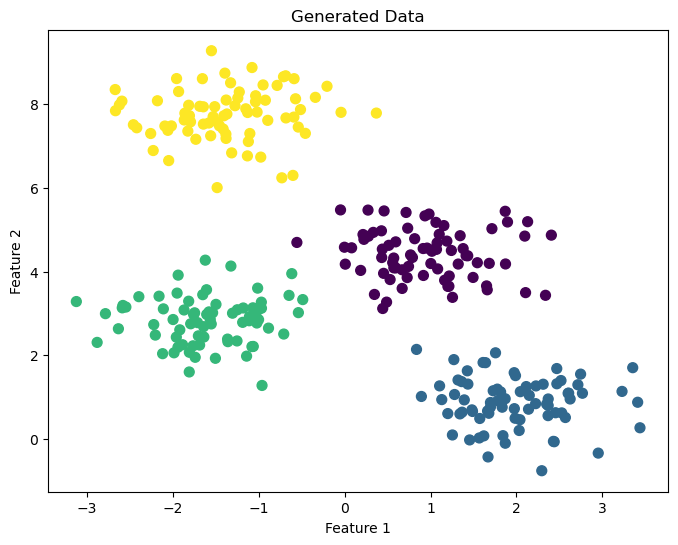

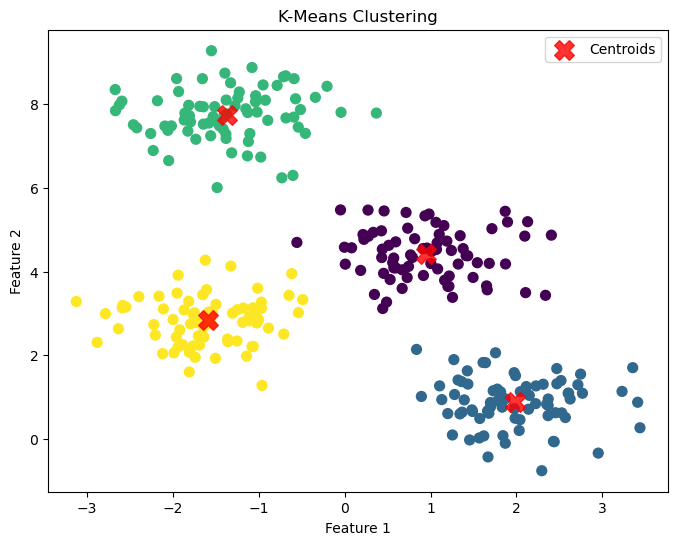

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate synthetic data
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# 2. Visualize the generated data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, c=y, cmap='viridis')
plt.title("Generated Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Apply K-Means clustering
k_means = KMeans(n_clusters=4, init='k-means++', max_iter=300, random_state=0, n_init=10)
y_kmeans = k_means.fit_predict(X)

# 4. Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

# 5. Plot the centroids
centers = k_means.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.8, marker='X', label='Centroids')

# 6. Add graph labels
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [3]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

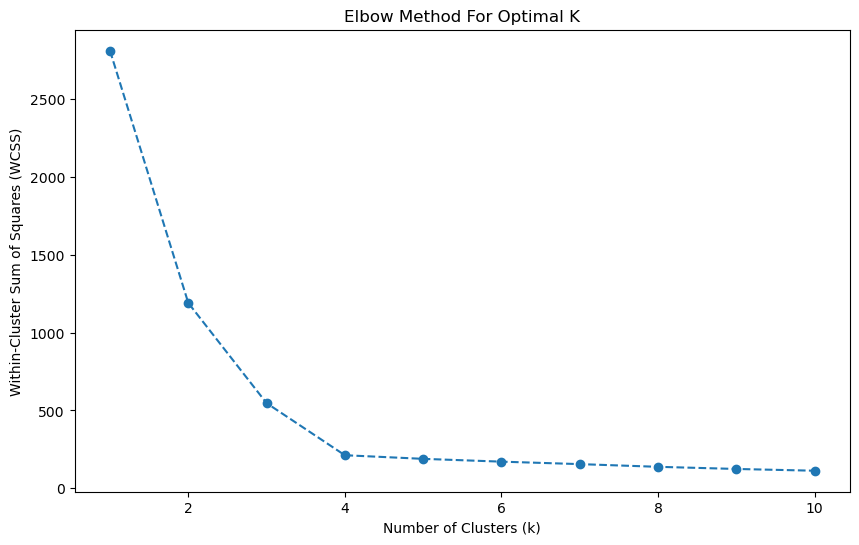

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Re-generate the same synthetic data for consistency
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

WCSS = []
max_k = 10  # Let's test k from 1 to 10

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, random_state=0, n_init=10)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)  # inertia_ is the WCSS

# Plotting the Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_k + 1), WCSS, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.show()